# K-Means Clustering: Customer Segmentation
## A step-by-step practical notebook

**Objective:** use K-Means to group customers with similar characteristics without using a target/label column.

### Dataset
`kmeans_customer_segmentation_dataset.csv` contains 300 synthetic customer records and these features:

- `Age`: customer age in years
- `Annual_Income_PKR`: annual income in Pakistani rupees
- `Spending_Score`: a score from 1 to 100
- `Visits_Per_Month`: average monthly visits
- `Average_Basket_PKR`: average basket value in PKR

The data is synthetic for teaching and does not describe real customers. A few values are intentionally missing so that data-quality handling can be practiced.

### Learning outcomes
By the end, you should be able to inspect data, prepare features, scale variables, select a candidate value of **K**, fit K-Means, visualize clusters, profile the groups, and explain limitations.

> **Key concept:** K-Means is unsupervised. We do not give it the correct customer segment in advance. The algorithm creates cluster assignments from the features we provide.


## 1. Import libraries
We use pandas for tabular data, matplotlib/seaborn for visualization, and scikit-learn for preprocessing, clustering and evaluation.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the dataset

Place `kmeans_customer_segmentation_dataset.csv` in the **same folder** as this notebook. If it is elsewhere, update the path in `DATA_PATH`.

If running in Google Colab, upload the CSV first or use the file-upload panel.

In [4]:
import os
DATA_PATH = "customer_spending.csv" if os.path.exists("customer_spending.csv") else "Coursework/Machine_Learning/customer_spending.csv"
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (300, 5)


,Age,Annual_Income_PKR,Spending_Score,Visits_Per_Month,Average_Basket_PKR
0,44,156378.0,NaN,9.3,12149
1,18,79789.0,60.118149,6.5,3865
2,32,171480.0,97.546152,5.9,11055
3,36,83651.0,45.365218,5.4,5370
4,30,62788.0,39.774119,3.0,2672


## 3. Understand the data
Check the number of rows/columns, data types, descriptive statistics and missing values before modeling.

In [5]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\\nData types:")
print(df.dtypes)

print("\\nMissing values per column:")
display(df.isna().sum().to_frame("Missing_Count"))

print("\\nSummary statistics:")
display(df.describe().T)

Rows: 300
Columns: 5
\nData types:
Age                     int64
Annual_Income_PKR     float64
Spending_Score        float64
Visits_Per_Month      float64
Average_Basket_PKR      int64
dtype: object
\nMissing values per column:


,Missing_Count
Age,0
Annual_Income_PKR,3
Spending_Score,3
Visits_Per_Month,0
Average_Basket_PKR,0


\nSummary statistics:


,count,mean,std,min,25%,50%,75%,max
Age,300.0,35.870000,11.375020,18.000000,27.000000,34.500000,44.000000,64.000000
Annual_Income_PKR,297.0,87929.717172,53860.547858,15000.000000,44842.000000,77609.000000,120445.000000,258335.000000
Spending_Score,297.0,52.815193,23.864726,3.192915,31.896917,53.658754,74.267146,99.644361
Visits_Per_Month,300.0,5.417333,2.969066,0.000000,2.700000,5.500000,7.800000,13.500000
Average_Basket_PKR,300.0,4609.500000,3114.903934,322.000000,2074.750000,3830.500000,5821.000000,12530.000000


## 4. Exploratory data analysis (EDA)

Histograms help us understand feature distributions. Scatter plots show relationships between pairs of features. EDA does not decide the clusters by itself; it helps us detect issues and understand the data before fitting the model.

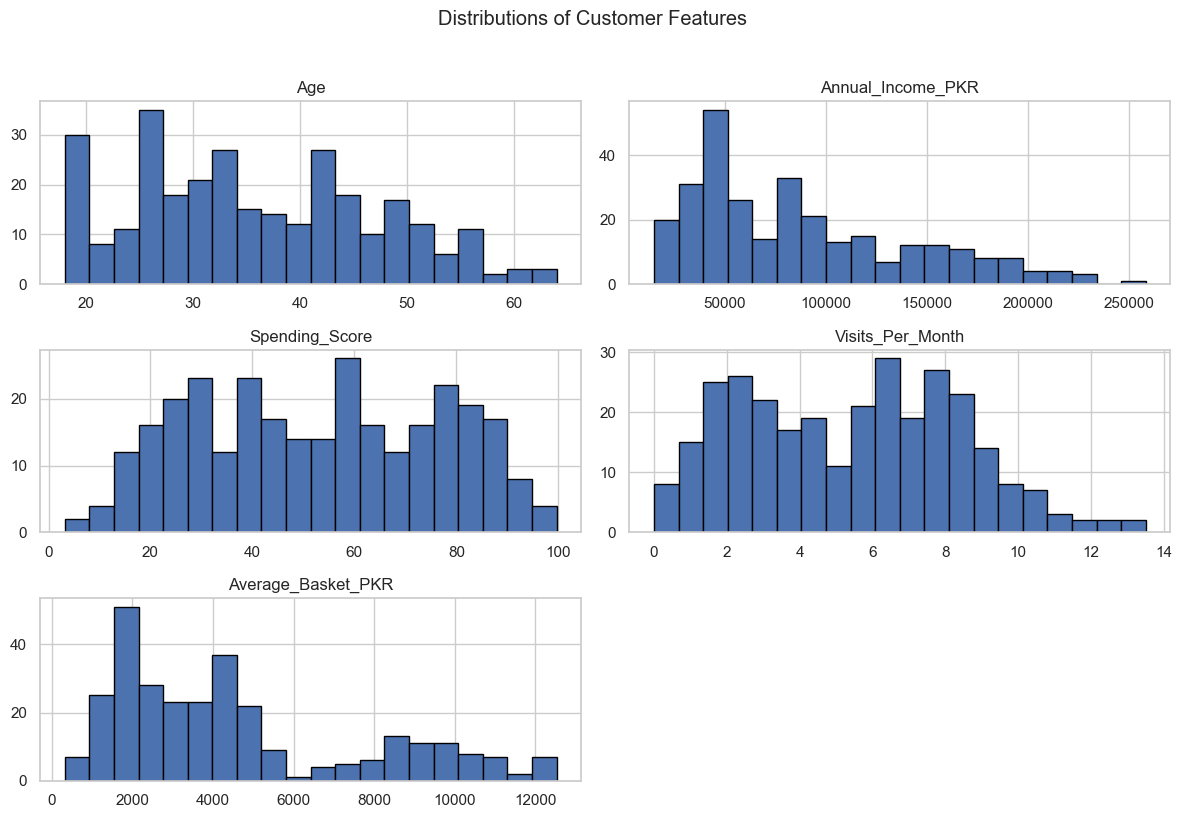

In [6]:
df.hist(figsize=(12, 8), bins=20, edgecolor="black")
plt.suptitle("Distributions of Customer Features", y=1.02)
plt.tight_layout()
plt.show()

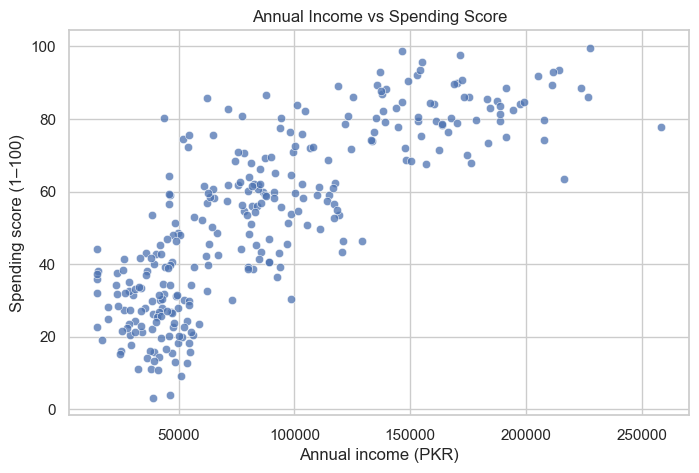

In [7]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Annual_Income_PKR",
    y="Spending_Score",
    alpha=0.75
)
plt.title("Annual Income vs Spending Score")
plt.xlabel("Annual income (PKR)")
plt.ylabel("Spending score (1–100)")
plt.show()

## 5. Select features for clustering

We will use the five customer characteristics below. We intentionally **do not** use an ID or target label. If features have very different units, K-Means can be dominated by the largest-scale variables, so scaling is important.

In [8]:
features = [
    "Age",
    "Annual_Income_PKR",
    "Spending_Score",
    "Visits_Per_Month",
    "Average_Basket_PKR"
]

X = df[features].copy()
display(X.head())

,Age,Annual_Income_PKR,Spending_Score,Visits_Per_Month,Average_Basket_PKR
0,44,156378.0,NaN,9.3,12149
1,18,79789.0,60.118149,6.5,3865
2,32,171480.0,97.546152,5.9,11055
3,36,83651.0,45.365218,5.4,5370
4,30,62788.0,39.774119,3.0,2672


## 6. Handle missing values

K-Means cannot fit directly on rows containing missing values. For this exercise, replace missing numeric values with the **median** of each feature. Median imputation is a simple baseline; in a real project, choose an approach appropriate to the data-generation process and document it.

In [9]:
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)

print("Missing values before imputation:", X.isna().sum().sum())
print("Missing values after imputation:", np.isnan(X_imputed).sum())

Missing values before imputation: 6
Missing values after imputation: 0


## 7. Scale the features

`StandardScaler` transforms each feature to approximately mean 0 and standard deviation 1. This prevents income or basket value, measured in thousands of PKR, from overwhelming age or spending score solely because of their numeric scale.

Fit preprocessing on training data only in predictive workflows. Here, we are exploring the complete dataset, so the scaler is fitted on all rows for this unsupervised exercise.

In [10]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("Scaled matrix shape:", X_scaled.shape)
print("Feature means after scaling (approximately 0):")
print(np.round(X_scaled.mean(axis=0), 3))
print("Feature standard deviations (approximately 1):")
print(np.round(X_scaled.std(axis=0), 3))

Scaled matrix shape: (300, 5)
Feature means after scaling (approximately 0):
[ 0.  0.  0. -0.  0.]
Feature standard deviations (approximately 1):
[1. 1. 1. 1. 1.]


## 8. Choose a candidate number of clusters (K)

K-Means requires us to choose K. Two common diagnostics are:

- **Elbow method:** plot inertia (within-cluster sum of squared distances) against K. Inertia always tends to decrease as K increases, so look for a point where improvement begins to flatten.
- **Silhouette score:** ranges from -1 to +1. Higher values generally indicate clusters that are more cohesive and better separated. It is not an absolute proof that a clustering is useful.

Use both diagnostics, cluster sizes, stability and business interpretation. Do not choose K from one score alone.

C:\Users\hasan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\hasan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.13_3.13.3824.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 554, in run
    

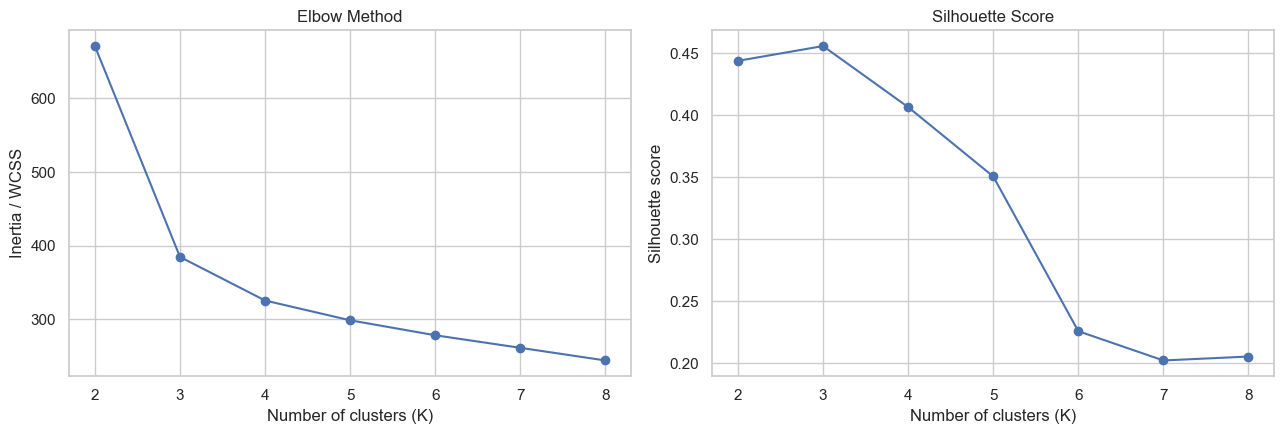

,K,Inertia,Silhouette_Score
0,2,670.901,0.444
1,3,384.779,0.456
2,4,325.651,0.406
3,5,298.811,0.351
4,6,278.503,0.226
5,7,261.452,0.202
6,8,244.323,0.206


In [11]:
inertias = []
silhouette_scores = []
k_values = range(2, 9)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Inertia / WCSS")

axes[1].plot(list(k_values), silhouette_scores, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Silhouette score")

plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertias,
    "Silhouette_Score": silhouette_scores
}).round(3))

### How to interpret the charts
- The elbow is a **visual heuristic**, not a guaranteed answer.
- The highest silhouette score may suggest a candidate K, but also inspect whether groups are useful and sufficiently large.
- For this teaching dataset, try **K = 3** as a starting hypothesis, then compare it with your diagnostics. The best K for a real dataset may differ.

## 9. Train the K-Means model
K-Means alternates between assigning each record to the nearest centroid and updating each centroid to the mean of its assigned records. `random_state` makes the initialization reproducible; `n_init=10` runs multiple initializations and retains a good solution.

In [12]:
K = 3

kmeans = KMeans(
    n_clusters=K,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_scaled)
df["Cluster"] = cluster_labels

print("Model fitted.")
print("Inertia:", round(kmeans.inertia_, 3))
print("Silhouette score:", round(silhouette_score(X_scaled, cluster_labels), 3))
display(df.head())

Model fitted.
Inertia: 384.779
Silhouette score: 0.456


,Age,Annual_Income_PKR,Spending_Score,Visits_Per_Month,Average_Basket_PKR,Cluster
0,44,156378.0,NaN,9.3,12149,1
1,18,79789.0,60.118149,6.5,3865,0
2,32,171480.0,97.546152,5.9,11055,1
3,36,83651.0,45.365218,5.4,5370,0
4,30,62788.0,39.774119,3.0,2672,2


## 10. Visualize the resulting clusters

This scatter plot uses income and spending score for a 2D view. The model was fitted using **all five scaled features**, not just the two plotted axes. A 2D visualization may hide differences in the other features.

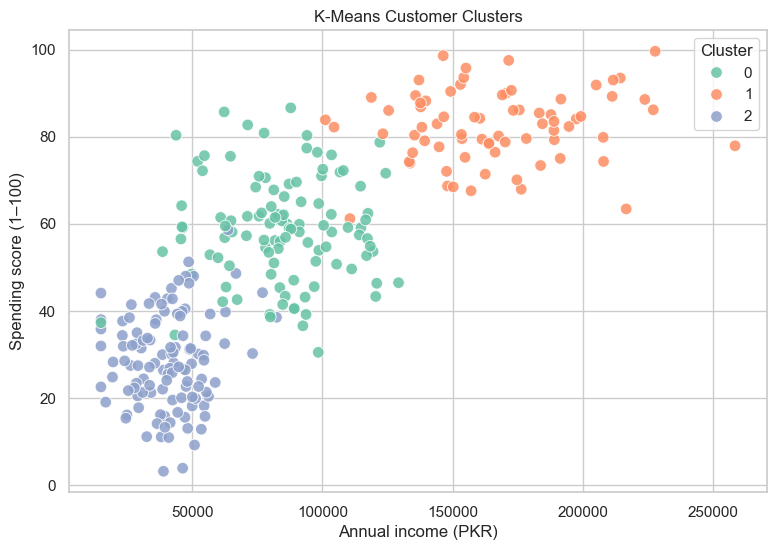

In [13]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="Annual_Income_PKR",
    y="Spending_Score",
    hue="Cluster",
    palette="Set2",
    s=70,
    alpha=0.85
)
plt.title("K-Means Customer Clusters")
plt.xlabel("Annual income (PKR)")
plt.ylabel("Spending score (1–100)")
plt.legend(title="Cluster")
plt.show()

## 11. Inspect cluster sizes

Cluster labels are arbitrary identifiers. Cluster 0 is not automatically “better” or “lower” than Cluster 1. Check whether clusters are reasonably sized and whether any tiny group needs further investigation.

In [14]:
cluster_sizes = df["Cluster"].value_counts().sort_index().rename("Customer_Count")
cluster_percent = (cluster_sizes / len(df) * 100).rename("Percentage")

size_summary = pd.concat([cluster_sizes, cluster_percent], axis=1)
display(size_summary.round(2))

,Customer_Count,Percentage
Cluster,,
0,108,36.00
1,74,24.67
2,118,39.33


## 12. Profile the clusters

Cluster profiling converts numeric group assignments into an interpretable summary. The table below reports average feature values for each cluster. Use the results to describe the observed groups rather than assigning stereotypes or assuming a cause.

In [15]:
cluster_profile = df.groupby("Cluster")[features].mean().round(2)
display(cluster_profile)

,Age,Annual_Income_PKR,Spending_Score,Visits_Per_Month,Average_Basket_PKR
Cluster,,,,,
0,39.08,84592.06,58.66,6.43,4207.74
1,46.39,166561.70,82.41,8.59,9401.11
2,26.33,40846.64,28.75,2.50,1972.31


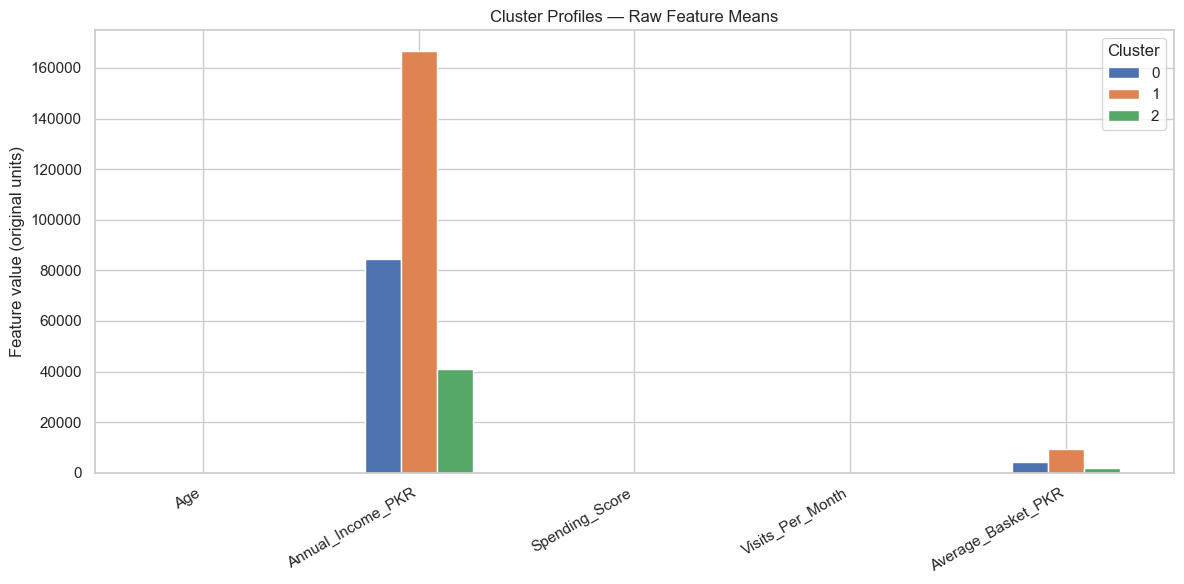

Note: features use different units, so compare values within each feature, not across different features.


In [16]:
cluster_profile.T.plot(kind="bar", figsize=(12, 6))
plt.title("Cluster Profiles — Raw Feature Means")
plt.ylabel("Feature value (original units)")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

print("Note: features use different units, so compare values within each feature, not across different features.")

## 13. Understand the centroids

`kmeans.cluster_centers_` contains centroids in **scaled feature space**, because the model was trained on scaled data. To interpret them in original units, reverse the scaling. (The imputer is not inverted here; centroids are feature means and inverse scaling is sufficient for unit conversion.)

In [17]:
centroids_scaled = kmeans.cluster_centers_
centroids_original = scaler.inverse_transform(centroids_scaled)

centroid_table = pd.DataFrame(
    centroids_original,
    columns=features
).round(2)

centroid_table.index.name = "Cluster"
display(centroid_table)

,Age,Annual_Income_PKR,Spending_Score,Visits_Per_Month,Average_Basket_PKR
Cluster,,,,,
0,39.08,84527.40,58.66,6.43,4207.74
1,46.39,166561.70,82.02,8.59,9401.11
2,26.33,41469.73,29.17,2.50,1972.31


## 14. How the K-Means algorithm works

1. **Initialize:** choose K starting centroids (scikit-learn's default uses K-Means++ initialization).
2. **Assign:** calculate each point's distance to each centroid and assign it to the nearest one.
3. **Update:** recompute each centroid as the mean of the points assigned to that cluster.
4. **Repeat:** continue assignment and update until convergence or the iteration limit.
5. **Evaluate:** review inertia, silhouette, cluster profiles and stability.

The objective for standard Euclidean K-Means is to minimize within-cluster sum of squared distances. It can converge to a local optimum, so initialization and repeated runs matter.

## 15. Common mistakes and limitations

- **Not scaling features:** large numeric ranges may dominate distance.
- **Using irrelevant features:** noisy dimensions can weaken clusters.
- **Assuming K is obvious:** use diagnostics and domain interpretation.
- **Treating cluster IDs as ranks:** labels are arbitrary.
- **Expecting irregular shapes:** K-Means works best for relatively compact, roughly spherical groups.
- **Ignoring outliers:** extreme values can pull centroids.
- **Overclaiming meaning:** clustering reveals patterns, not causation or guaranteed customer types.
- **Skipping validation:** check stability, sampling effects and whether actions based on clusters are useful.

## 16. Practice tasks

1. Change `K = 3` to `K = 2`, then `K = 4`. How do the cluster sizes and profiles change?
2. Fit K-Means using only `Annual_Income_PKR` and `Spending_Score`. Compare the result with the five-feature model.
3. Try `RobustScaler` and compare the results.
4. Identify which cluster has the highest average basket value.
5. Write a short business summary: what are the groups, what evidence supports the description, and what would you validate before acting?
6. Explain why a higher K usually lowers inertia, even when the extra clusters are not useful.

## 17. Key takeaways

- K-Means is an **unsupervised clustering algorithm**; no target labels are provided.
- It groups observations by distance to centroids and repeatedly updates those centroids.
- Data cleaning and feature scaling are essential when numeric units differ.
- Elbow and silhouette are helpful diagnostics, not automatic truth.
- Cluster profiling and domain validation turn model output into useful insights.
- Always explain assumptions and limitations alongside results.

### Files needed
Keep this notebook and `kmeans_customer_segmentation_dataset.csv` in the same folder. Run the notebook from top to bottom.